# Simulation and model smoke test

The simulator returns a dict whose top-level keys can be passed directly to `model_coupling`.


In [1]:
import arviz as az
import jax
import matplotlib.pyplot as plt
import numpy as np
import numpyro
from matplotlib.lines import Line2D
from coupling_sources.core.data import StimulusSpec
from coupling_sources.core.model import model_coupling
from coupling_sources.core.priors import coupling_parameter_sites, sample_coupling_parameter_draws
from coupling_sources.core.simulator import simulate_coupling
from coupling_sources.core.stimuli import generate_stimulus

In [2]:
numpyro.set_host_device_count(4)
numpyro.set_platform("cpu")

In [3]:
stimuli = generate_stimulus(
    StimulusSpec(
        seed=101,
        n_participants=1,
        n_sources=4,
        n_rounds=2,
        n_trials_full=4,
        n_trials_partial=2,
        sigma=0.55,
        lam=0.8,
        min_mean_angle_difference=0.05,
        coupled_sources=(0, 1),
    )
)

simulation = simulate_coupling(
    seed=201,
    batch=stimuli,
    parameters={"alpha": 0.2, "gain_y": 1.0, "gain_z": 1.0, "kappa": 8.0},
)
simulation.visible_reports.shape, simulation.responses.shape

((1, 2, 6, 4), (1, 2, 6))

In [4]:
seeded_model = numpyro.handlers.seed(model_coupling, jax.random.PRNGKey(0))
seeded_model(simulation)
"model ran"

'model ran'

## Render the model with three trials

This section creates a minimal three-trial batch and renders the NumPyro model graph against it.


visible_reports shape: (1, 1, 3, 4)


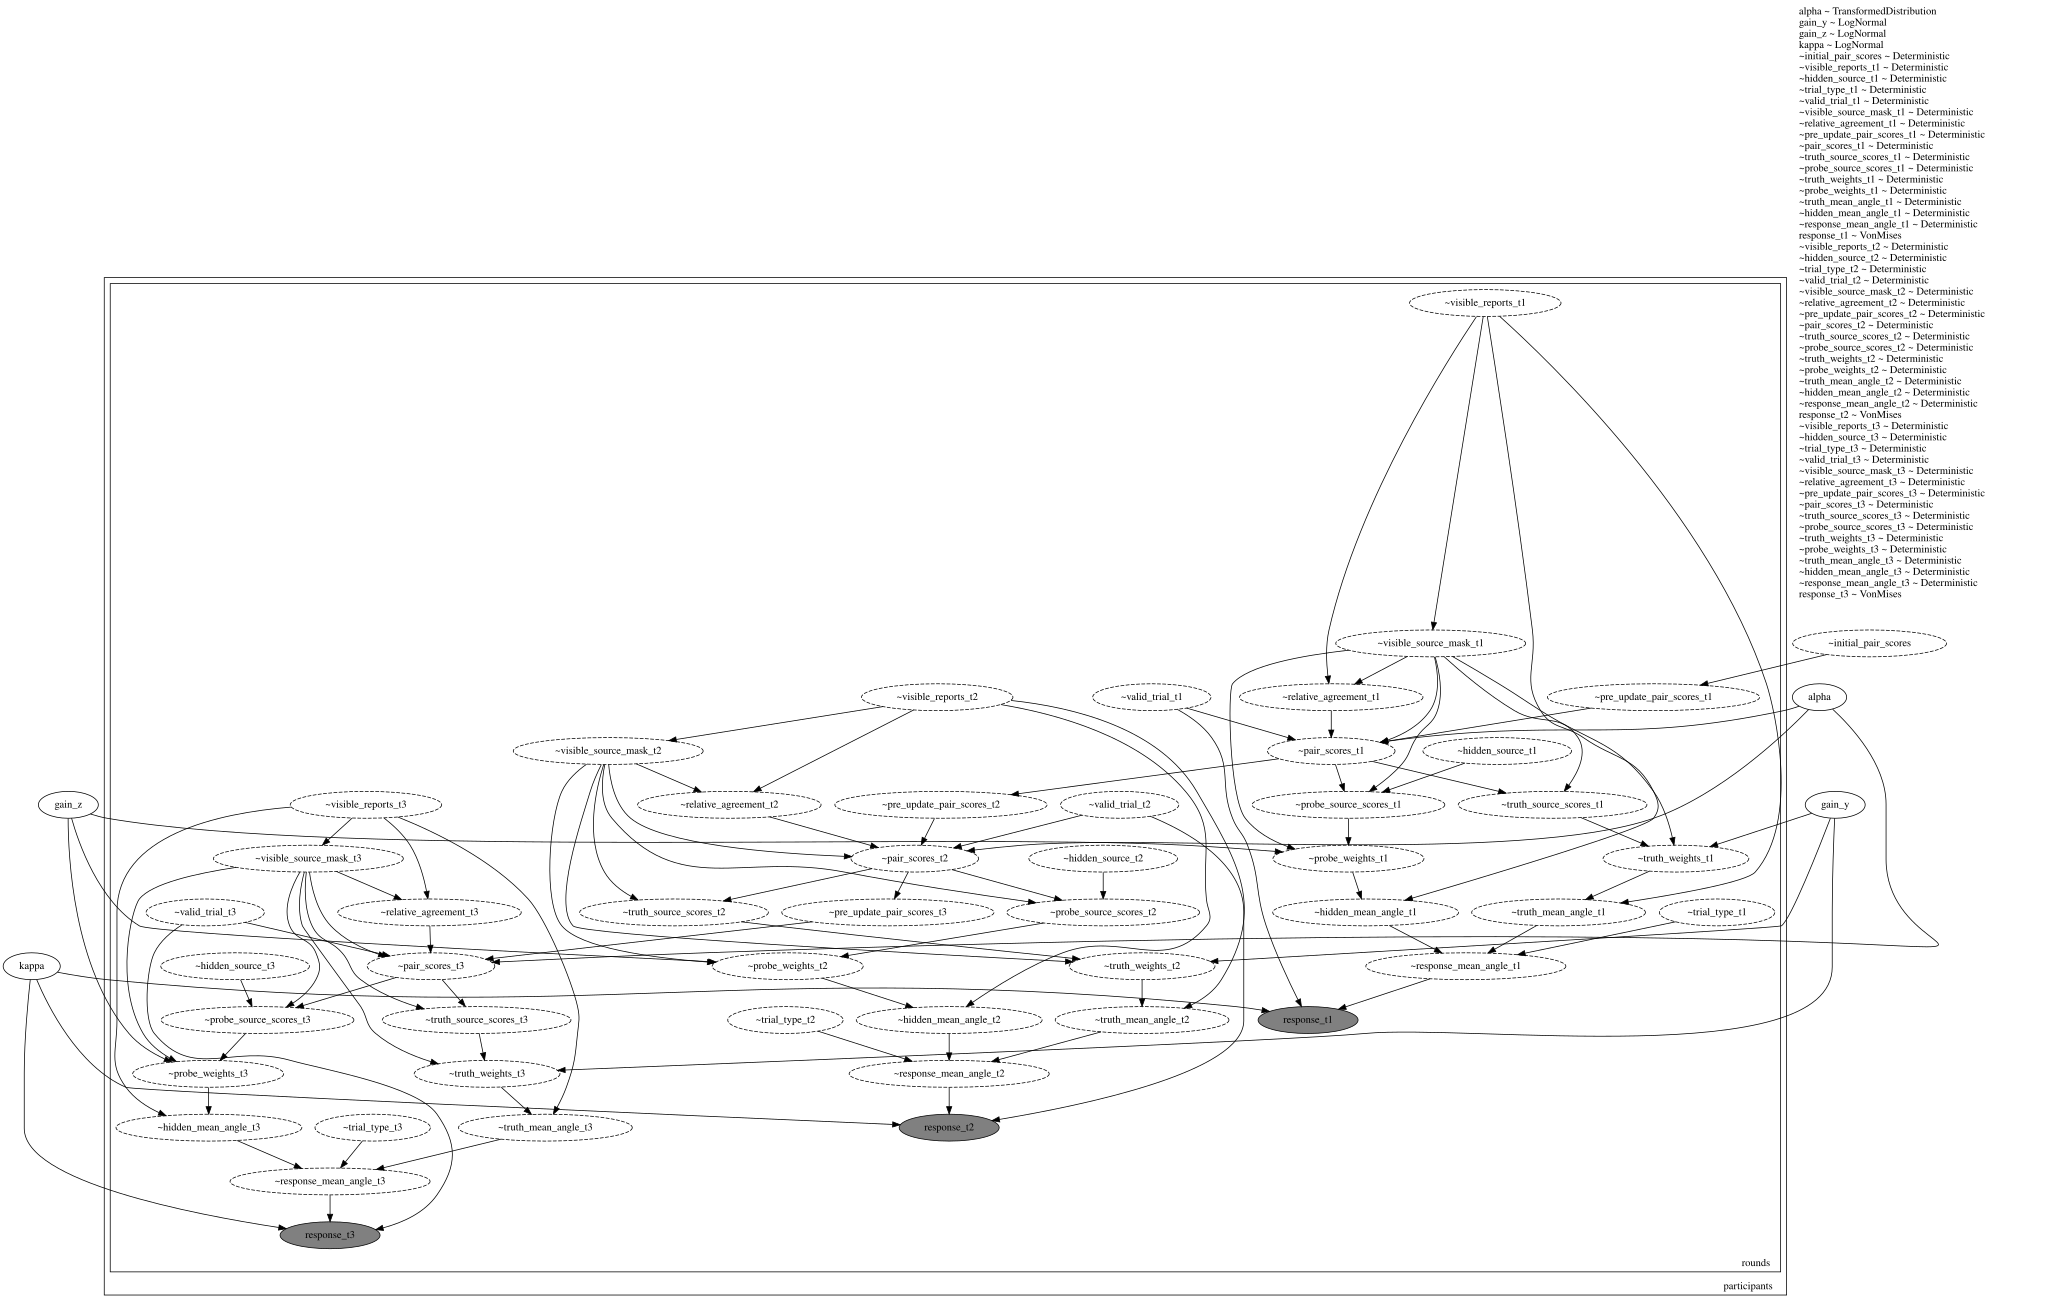

In [5]:
N_RENDER_TRIALS = 3

render_stimuli = generate_stimulus(
    StimulusSpec(
        seed=301,
        n_participants=1,
        n_sources=4,
        n_rounds=1,
        n_trials_full=N_RENDER_TRIALS - 1,
        n_trials_partial=1,
        sigma=0.55,
        lam=0.8,
        min_mean_angle_difference=0.05,
        coupled_sources=(0, 1),
    )
)

render_simulation = simulate_coupling(
    seed=302,
    batch=render_stimuli,
    parameters={"alpha": 0.2, "gain_y": 1.0, "gain_z": 1.0, "kappa": 16.0},
)

print("visible_reports shape:", render_simulation.visible_reports.shape)
numpyro.render_model(
    model_coupling,
    model_args=(render_simulation,),
    render_distributions=True,
)

## Stimuli, simulation, MCMC fit, and posterior recovery

This section runs the full workflow explicitly: generate stimuli, simulate responses from known parameters, fit the model with MCMC, then overlay posterior distributions with the ground-truth parameter values.


In [10]:
PARAMETER_SITES = coupling_parameter_sites()
GROUND_TRUTH = {"alpha": 0.35, "gain_y": 1.2, "gain_z": 0.8, "kappa": 6.0}

fit_stimuli = generate_stimulus(
    StimulusSpec(
        seed=401,
        n_participants=120,
        n_sources=4,
        n_rounds=1,
        n_trials_full=80,
        n_trials_partial=40,
        sigma=0.55,
        lam=0.8,
        min_mean_angle_difference=0.05,
        coupled_sources=(0, 1),
    )
)

fit_stimuli.visible_reports.shape

(120, 1, 120, 4)

In [11]:
fit_simulation = simulate_coupling(
    seed=402,
    batch=fit_stimuli,
    parameters=GROUND_TRUTH,
)

fit_simulation.responses.shape

(120, 1, 120)

In [12]:
kernel = numpyro.infer.NUTS(
    model_coupling,
    target_accept_prob=0.8,
    max_tree_depth=8,
)
mcmc = numpyro.infer.MCMC(
    kernel,
    num_warmup=300,
    num_samples=800,
    num_chains=4,
    progress_bar=True,
)
mcmc.run(
    jax.random.PRNGKey(403),
    fit_simulation,
    extra_fields=("diverging",),
)

posterior_samples = {
    name: np.asarray(values).reshape(-1)
    for name, values in mcmc.get_samples().items()
    if name in PARAMETER_SITES
}
mcmc.print_summary()

  0%|          | 0/1100 [00:00<?, ?it/s]

  0%|          | 0/1100 [00:00<?, ?it/s]

  0%|          | 0/1100 [00:00<?, ?it/s]

  0%|          | 0/1100 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
     alpha      0.50      0.14      0.49      0.27      0.70    936.71      1.00
    gain_y      1.06      0.28      1.05      0.60      1.52   1156.89      1.00
    gain_z      0.85      0.28      0.84      0.41      1.31   2046.01      1.00
     kappa      5.99      0.07      5.99      5.88      6.09   3341.42      1.00

Number of divergences: 0


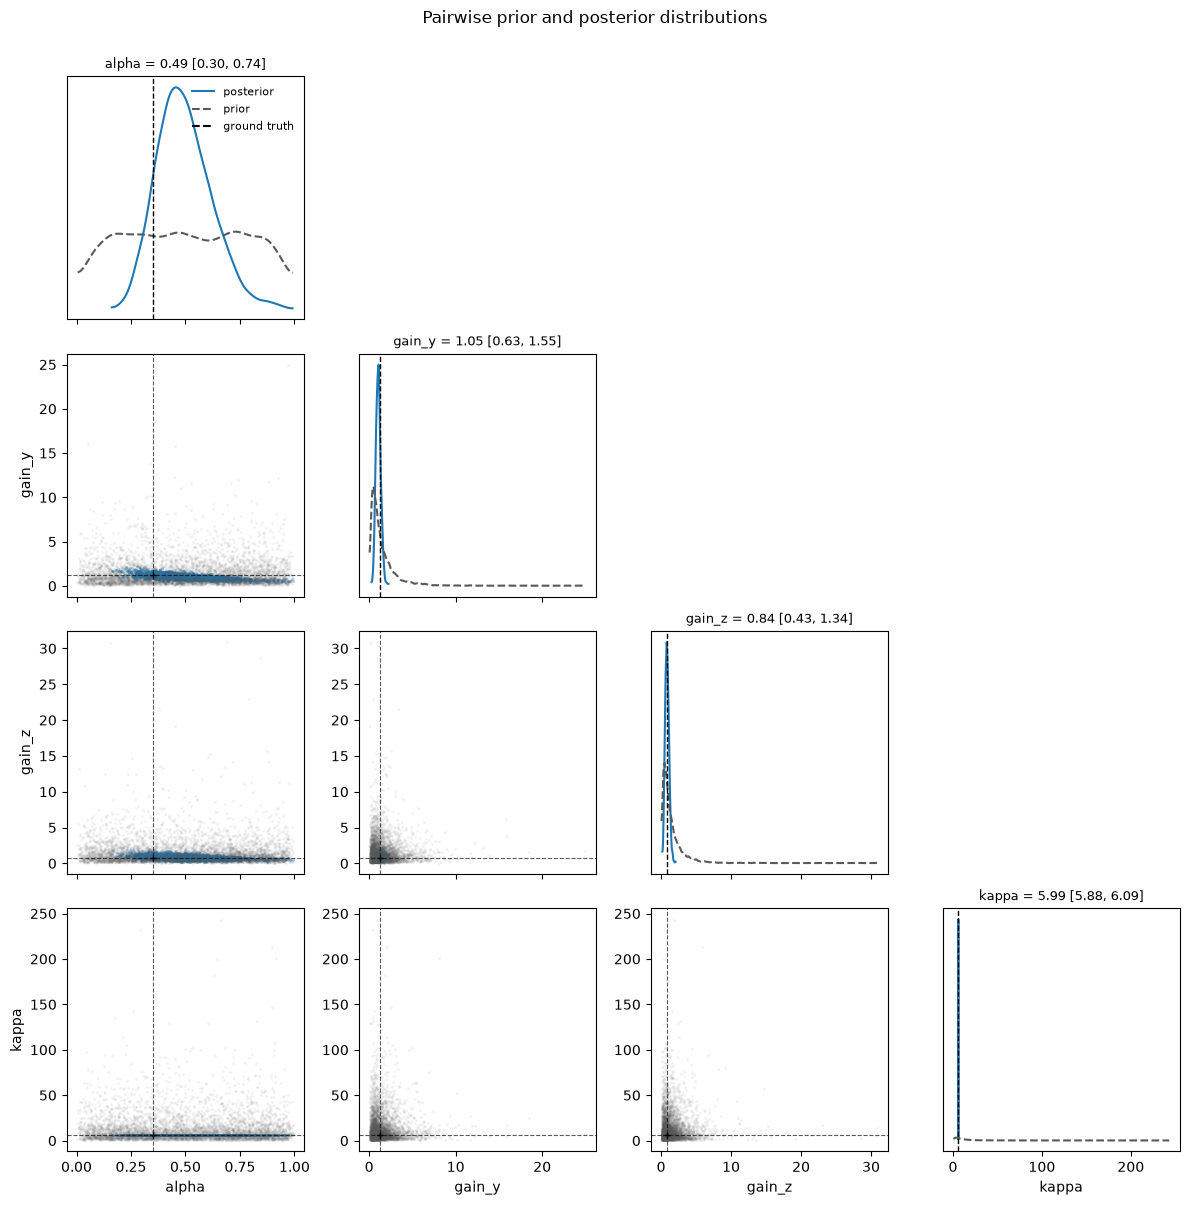

In [13]:
prior_samples = sample_coupling_parameter_draws(seed=404, draws=5_000)
idata = az.from_dict(
    {"posterior": posterior_samples, "prior": prior_samples},
    sample_dims=["draw"],
)

pair_args = dict(
    var_names=list(PARAMETER_SITES),
    triangle="lower",
    marginal=True,
    marginal_kind="kde",
    backend="matplotlib",
)
styles = {
    "posterior": {
        "scatter": {"color": "tab:blue", "alpha": 0.35, "s": 4},
        "dist": {"color": "tab:blue"},
    },
    "prior": {
        "scatter": {"color": "0.35", "alpha": 0.08, "s": 4},
        "dist": {"color": "0.35", "linestyle": "--"},
    },
}

pair_plot = az.plot_pair(
    idata,
    group="posterior",
    visuals=styles["posterior"],
    figure_kwargs={"figsize": (12, 12)},
    **pair_args,
)
az.plot_pair(
    idata,
    group="prior",
    plot_matrix=pair_plot,
    visuals=styles["prior"],
    **pair_args,
)

axes = pair_plot.viz["plot"].values
for row, y_parameter in enumerate(PARAMETER_SITES):
    for col, x_parameter in enumerate(PARAMETER_SITES[: row + 1]):
        ax = axes[row, col]
        if row == col:
            values = posterior_samples[x_parameter]
            ax.axvline(GROUND_TRUTH[x_parameter], color="black", linestyle="--", linewidth=1.0)
            lo, mid, hi = np.quantile(values, [0.05, 0.5, 0.95])
            ax.set_title(f"{x_parameter} = {mid:.2f} [{lo:.2f}, {hi:.2f}]", fontsize=9)
            ax.set_yticks([])
            ax.set_ylabel("")
        else:
            ax.axvline(GROUND_TRUTH[x_parameter], color="black", linestyle="--", linewidth=0.8, alpha=0.65)
            ax.axhline(GROUND_TRUTH[y_parameter], color="black", linestyle="--", linewidth=0.8, alpha=0.65)
            ax.plot(GROUND_TRUTH[x_parameter], GROUND_TRUTH[y_parameter], "k+", markersize=5)

axes[0, 0].legend(
    handles=[
        Line2D([], [], color="tab:blue", label="posterior"),
        Line2D([], [], color="0.35", linestyle="--", label="prior"),
        Line2D([], [], color="black", linestyle="--", label="ground truth"),
    ],
    frameon=False,
    fontsize=8,
)
plt.gcf().suptitle("Pairwise prior and posterior distributions", y=1.0)
plt.gcf().tight_layout()
plt.show()